# Boreas-RT dataset overview
Inspect a downloaded sequence through the public `boreas_dataset` API. No downloads occur and no raw clouds are loaded here. All time bounds are absolute UTC seconds; plots use relative time. Optional missing sensors are listed rather than loaded.

The reference poses come from Applanix/GNSS/INS and are **ground truth**, not independently estimated LiDAR odometry. [Official Boreas-RT reference](https://github.com/utiasASRL/pyboreas/blob/master/DATA_RT_REFERENCE.md).

In [1]:
from pathlib import Path
import os
import sys

# Run from the repository root or this notebook directory; editable installs also work.
for parent in (Path.cwd(), *Path.cwd().parents):
    if (parent / "src/boreas_dataset").is_dir():
        sys.path.insert(0, str(parent / "src"))
        break

import numpy as np
import matplotlib.pyplot as plt
from boreas_dataset import (
    BoreasDataset, relative_seconds, timestamp_statistics, nearest_timestamps,
    motion_magnitudes, accumulate_lidar_scans,
)
get_ipython().run_line_magic("matplotlib", "inline")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10})
COLORS = ["#2878B5", "#E07A28", "#36865C"]

In [2]:
# None uses BOREAS_DATA_ROOT, then the documented local example path.
DATA_ROOT = os.environ.get("BOREAS_DATA_ROOT")
SEQUENCE_ID = "boreas-2024-12-03-12-54"
SHOW_PLOTS = True

def show_figure(fig):
    fig.tight_layout()
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)

## Available sequences, sensors and files

In [3]:
dataset = BoreasDataset(DATA_ROOT)
print("Dataset root:", dataset.root)
print("Sequences:", dataset.sequences)
sequence = dataset.sequence(SEQUENCE_ID)
inventory = sequence.inventory()
print("Sensors:", inventory["sensors"])
for filename, exists in inventory["expected_files"].items():
    print(f"{'available' if exists else 'MISSING  '}  {filename}")
print("Trajectories:", inventory["trajectories"])
print("Map-like files:", inventory["map_like_files"] or "None found")

Dataset root: D:\Downloads\MobRobLab\BoreasDataset
Sequences: ['boreas-2024-12-03-12-54']


Sensors: {'imu': ['dmu', 'dmu_infilled', 'aeva', 'applanix'], 'lidar': ['velodyne', 'aeva'], 'detected_unimplemented': ['radar', 'camera']}
available  imu/dmu_imu.csv
available  imu/dmu_imu_infilled.csv
available  imu/aeva_imu.csv
available  applanix/imu.csv
available  applanix/lidar_poses.csv
available  applanix/gps_post_process.csv
available  calib/T_applanix_lidar.txt
available  calib/T_applanix_dmu.txt
Trajectories: ['aeva_poses.csv', 'camera_poses.csv', 'lidar_poses.csv', 'radar_poses.csv']
Map-like files: None found


## Duration, counts, coverage and acquisition gaps
`summary()` explicitly reads sensor CSVs one at a time. It leaves every point cloud unloaded. Gap detection uses 1.5 times the median sample period and does not modify measurements. Applanix is included as a correlated reference; a warning is expected.

In [4]:
summary = sequence.summary()
coverage = summary["coverage"]
print(f"Recording coverage span: {summary['duration_s']:.3f} s")
print("Common sensor interval [UTC s]:", summary["common_interval_s"])
for name, stats in coverage.items():
    print(f"{name:20s} N={stats['count']:7d}, duration={stats['duration_s']:8.3f} s, "
          f"median frequency={stats['frequency_hz']}, gaps={len(stats['gap_indices'])}")
    print("  UTC endpoints:", stats["start_s"], stats["end_s"], "maximum dt [s]:", stats["max_dt_s"])

\\wsl.localhost\Ubuntu\home\camel\Skoltech\Mobile_Robotics_Lab\nn-obs-calib\src\boreas_dataset\imu.py:89: UserWarning: Applanix IMU contributes to ground truth and is not independent calibration input
  return load_imu_file(Path(sequence_root) / IMU_SOURCES[source][0], source=source, time_start=time_start, time_end=time_end)


Recording coverage span: 1066.978 s
Common sensor interval [UTC s]: (1733248461.986694, 1733249447.730438)
imu/dmu              N= 196429, duration= 985.974 s, median frequency=200.1973144731447, gaps=26
  UTC endpoints: 1733248461.8860826 1733249447.8601086 maximum dt [s]: 0.304695296
imu/dmu_infilled     N= 197195, duration= 985.957 s, median frequency=200.00256003276843, gaps=0
  UTC endpoints: 1733248461.8860826 1733249447.8434622 maximum dt [s]: 0.004999936
imu/aeva             N= 102711, duration=1027.110 s, median frequency=100.0, gaps=2
  UTC endpoints: 1733248441.387708 1733249468.497708 maximum dt [s]: 0.022027
imu/applanix         N= 213397, duration=1066.978 s, median frequency=200.0, gaps=0
  UTC endpoints: 1733248421.5271673 1733249488.5048292 maximum dt [s]: 0.0050008000000000006
lidar/velodyne       N=   9480, duration= 985.744 s, median frequency=9.640505548110943, gaps=0
  UTC endpoints: 1733248461.986694 1733249447.730438 maximum dt [s]: 0.114014
gt/lidar            

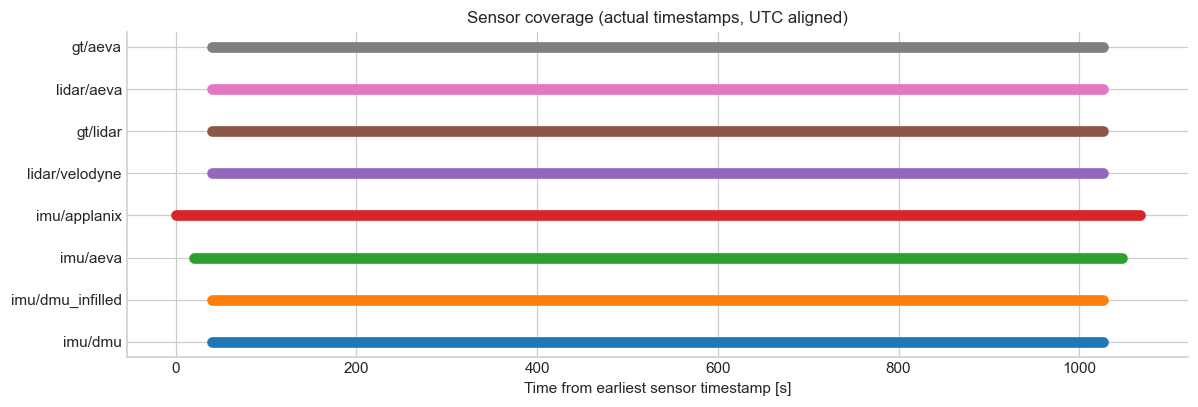

In [5]:
nonempty = {name: stats for name, stats in coverage.items() if stats["count"]}
origin = min((v["start_s"] for v in nonempty.values()), default=0)
fig, ax = plt.subplots(figsize=(11, 3.8))
for row, (name, stats) in enumerate(nonempty.items()):
    ax.plot([stats["start_s"] - origin, stats["end_s"] - origin], [row, row], lw=7, solid_capstyle="round")
ax.set(yticks=range(len(nonempty)), yticklabels=list(nonempty), xlabel="Time from earliest sensor timestamp [s]",
       title="Sensor coverage (actual timestamps, UTC aligned)")
show_figure(fig)

## Actual extrinsic calibration matrices

In [6]:
calibrations = sequence.calibrations
for name, T in calibrations.items():
    print(name, "— maps the final named frame into the first named frame")
    print(np.array2string(T, precision=6, suppress_small=True))
print("Required primary extrinsics:", {key: key in calibrations for key in
      ["T_applanix_dmu", "T_applanix_lidar"]})

T_aeva_lidar — maps the final named frame into the first named frame
[[ 0.686156  0.727451  0.00224  -0.306169]
 [-0.727447  0.686159 -0.002627 -0.380114]
 [-0.003448  0.000173  0.999994  0.213249]
 [ 0.        0.        0.        1.      ]]
T_applanix_dmu — maps the final named frame into the first named frame
[[ 0.999951 -0.009823 -0.00142   0.      ]
 [-0.009824 -0.999952 -0.000242  0.      ]
 [-0.001418  0.000256 -0.999999 -0.15    ]
 [ 0.        0.        0.        1.      ]]
T_applanix_lidar — maps the final named frame into the first named frame
[[ 0.734962 -0.678108  0.        0.      ]
 [ 0.678108  0.734962  0.        0.      ]
 [ 0.        0.        1.        0.13    ]
 [ 0.        0.        0.        1.      ]]
T_applanix_wheel — maps the final named frame into the first named frame
[[ 0.99956   0.029665  0.       -0.813993]
 [-0.029665  0.99956   0.       -0.455312]
 [ 0.        0.        1.       -1.61    ]
 [ 0.        0.        0.        1.      ]]
T_camera_lidar — maps 

## LiDAR ground-truth trajectory
The fixed world frame is `ENU_ref`. Matrices are `T_world_lidar`; the CSV angles are radians and use the passive yaw/pitch/roll convention implemented by the official development kit. No recentering is applied to the stored trajectory.

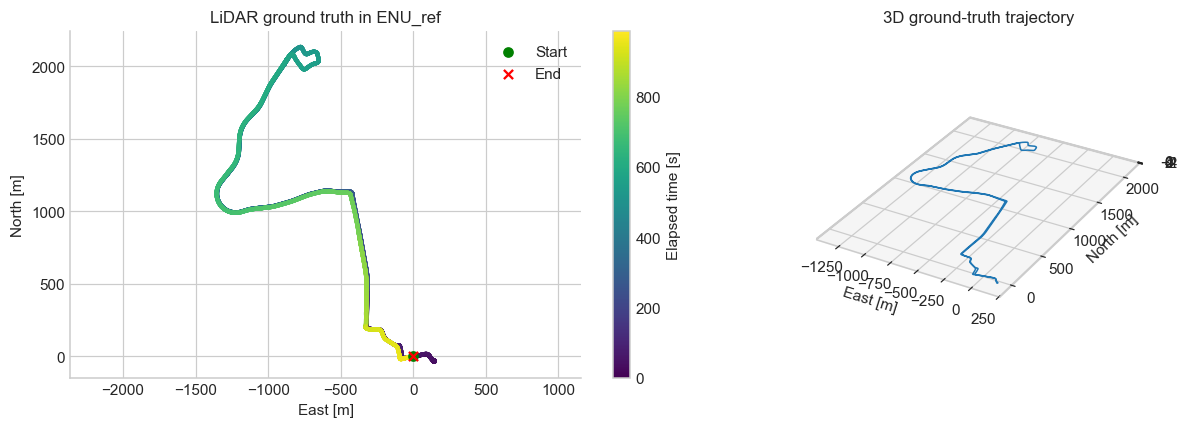

In [7]:
if (sequence.root / "applanix/lidar_poses.csv").is_file():
    trajectory = sequence.lidar_poses()
    xyz = trajectory.poses_T_W_L[:, :3, 3]
    if len(xyz):
        t = relative_seconds(trajectory.timestamps_ns)
        fig = plt.figure(figsize=(12, 4))
        ax = fig.add_subplot(121)
        scatter = ax.scatter(xyz[:, 0], xyz[:, 1], c=t, s=3, cmap="viridis")
        ax.scatter(*xyz[0, :2], marker="o", c="green", label="Start")
        ax.scatter(*xyz[-1, :2], marker="x", c="red", label="End")
        ax.set(xlabel="East [m]", ylabel="North [m]", title="LiDAR ground truth in ENU_ref")
        ax.set_aspect("equal", adjustable="datalim")
        ax.legend()
        fig.colorbar(scatter, ax=ax, label="Elapsed time [s]")
        ax3 = fig.add_subplot(122, projection="3d")
        ax3.plot(*xyz.T, lw=1)
        ax3.set(xlabel="East [m]", ylabel="North [m]", zlabel="Up [m]", title="3D ground-truth trajectory")
        ax3.set_aspect('equal')
        show_figure(fig)
else:
    print("LiDAR ground truth is unavailable in this partial download.")

## DMU timestamp statistics and dropouts

{'count': 196429, 'start_s': 1733248461.8860826, 'end_s': 1733249447.8601086, 'duration_s': 985.974025984, 'median_dt_s': 0.004995072000000001, 'frequency_hz': 200.1973144731447, 'min_dt_s': 0.004994816, 'max_dt_s': 0.304695296}
Gap count: 26
First ten gap durations [s]: [0.29470541 0.29470515 0.28971034 0.3046953  0.01498496 0.27472538
 0.02997018 0.25974016 0.29470541 0.29970048]


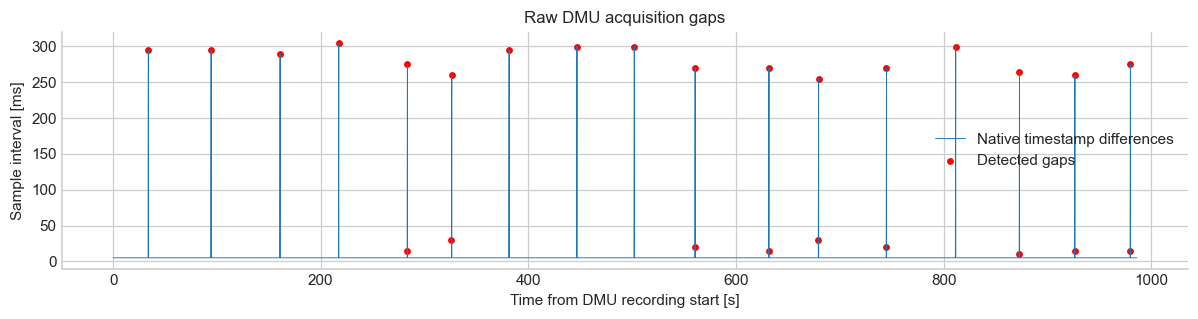

In [8]:
if "dmu" in sequence.sensors["imu"]:
    imu = sequence.imu()
    stats = timestamp_statistics(imu.timestamps_ns)
    print({key: value for key, value in stats.items() if key not in ["gap_indices", "gap_durations_s"]})
    print("Gap count:", len(stats["gap_indices"]))
    print("First ten gap durations [s]:", stats["gap_durations_s"][:10])
    dt = np.diff(imu.timestamps_ns).astype(float) * 1e-9
    fig, ax = plt.subplots(figsize=(11, 3))
    ax.plot(relative_seconds(imu.timestamps_ns)[1:], dt * 1000, lw=.6, label="Native timestamp differences")
    gaps = stats["gap_indices"]
    ax.scatter(relative_seconds(imu.timestamps_ns)[gaps + 1], dt[gaps] * 1000,
               color="red", s=12, label="Detected gaps")
    ax.set(xlabel="Time from DMU recording start [s]", ylabel="Sample interval [ms]", title="Raw DMU acquisition gaps")
    ax.legend()
    show_figure(fig)
else:
    print("Raw DMU unavailable; see inventory for alternative sources.")

## Compare all IMU sources
Compare every available source from `dmu`, `dmu_infilled`, `aeva`, and `applanix`. Counts/rates/gaps describe native acquisition. Axis means and standard deviations describe this moving recording; they are **not sensor-noise estimates**. Axes remain in each sensor's native frame, so component means must not be compared as if their frames coincide. Norm overlays are rotation-invariant, but Applanix acceleration is a processed reference signal and does not share the raw gravity-inclusive accelerometer convention.

In [9]:
import pandas as pd
from IPython.display import display
from boreas_dataset.sensor_statistics import imu_statistics
IMU_COMPARISON_SOURCES = ("dmu", "dmu_infilled", "aeva", "applanix")
imu_comparison = {source: sequence.imu(source) for source in IMU_COMPARISON_SOURCES
                  if source in sequence.sensors["imu"]}
missing_imus = [source for source in IMU_COMPARISON_SOURCES if source not in imu_comparison]
print("Missing optional sources:", missing_imus or "none")
imu_table = pd.DataFrame([imu_statistics(stream) for stream in imu_comparison.values()]).set_index("source")
display(imu_table[["frame", "samples", "duration_s", "median_rate_hz", "gaps", "max_dt_ms",
                   "gyro_norm_p50_radps", "gyro_norm_p95_radps", "accel_norm_p50_mps2",
                   "resampled", "independent_of_ground_truth"]])
axis_rows = []
for source, row in imu_table.iterrows():
    for axis, label in enumerate(("x", "y", "z")):
        axis_rows.append({"source": source, "native_axis": label,
                          "gyro_mean_radps": row["gyro_axis_mean_radps"][axis],
                          "gyro_std_radps": row["gyro_axis_std_radps"][axis],
                          "accel_mean_mps2": row["accel_axis_mean_mps2"][axis],
                          "accel_std_mps2": row["accel_axis_std_mps2"][axis]})
display(pd.DataFrame(axis_rows).set_index(["source", "native_axis"]))

\\wsl.localhost\Ubuntu\home\camel\Skoltech\Mobile_Robotics_Lab\nn-obs-calib\src\boreas_dataset\imu.py:89: UserWarning: Applanix IMU contributes to ground truth and is not independent calibration input
  return load_imu_file(Path(sequence_root) / IMU_SOURCES[source][0], source=source, time_start=time_start, time_end=time_end)


Missing optional sources: none


,frame,samples,duration_s,median_rate_hz,gaps,max_dt_ms,gyro_norm_p50_radps,gyro_norm_p95_radps,accel_norm_p50_mps2,resampled,independent_of_ground_truth
source,,,,,,,,,,,
dmu,dmu,196429,985.974026,200.197314,26,304.695296,0.026247,0.273617,9.864863,False,True
dmu_infilled,dmu,197195,985.957380,200.002560,0,4.999936,0.026194,0.273920,9.863520,True,True
aeva,aeva_imu,102711,1027.110000,100.000000,2,22.027000,0.029106,0.266497,9.940100,False,True
applanix,applanix,213397,1066.977662,200.000000,0,5.000800,0.023160,0.261070,0.915117,False,False


gyro_mean_radps  gyro_std_radps  accel_mean_mps2  \
source       native_axis                                                     
dmu          x              -4.598969e-04        0.025969        -0.145960   
             y               1.099830e-04        0.021192        -0.044036   
             z               4.138280e-05        0.110734        -9.781558   
dmu_infilled x              -4.510539e-04        0.025860        -0.146146   
             y               1.186550e-04        0.021078        -0.042891   
             z              -5.691332e-05        0.110840        -9.781596   
aeva         x              -9.036537e-03        0.020247         0.179837   
             y              -1.021492e-02        0.025126         0.073031   
             z              -6.319876e-03        0.108318         9.857099   
applanix     x              -3.746661e-04        0.024863         0.019129   
             y              -2.309053e-05        0.020445        -0.005652   
             z               9.518972e-07        0.106551        -0.007403   

                          accel_std_mps2  
source       native_axis                  
dmu          x                  0.981789  
             y                  1.077730  
             z                  0.424494  
dmu_infilled x                  0.973986  
             y                  1.068948  
             z                  0.406940  
aeva         x                  1.090728  
             y                  0.988098  
             z                  0.623594  
applanix     x                  0.915228  
             y                  1.007875  
             z                  0.399666

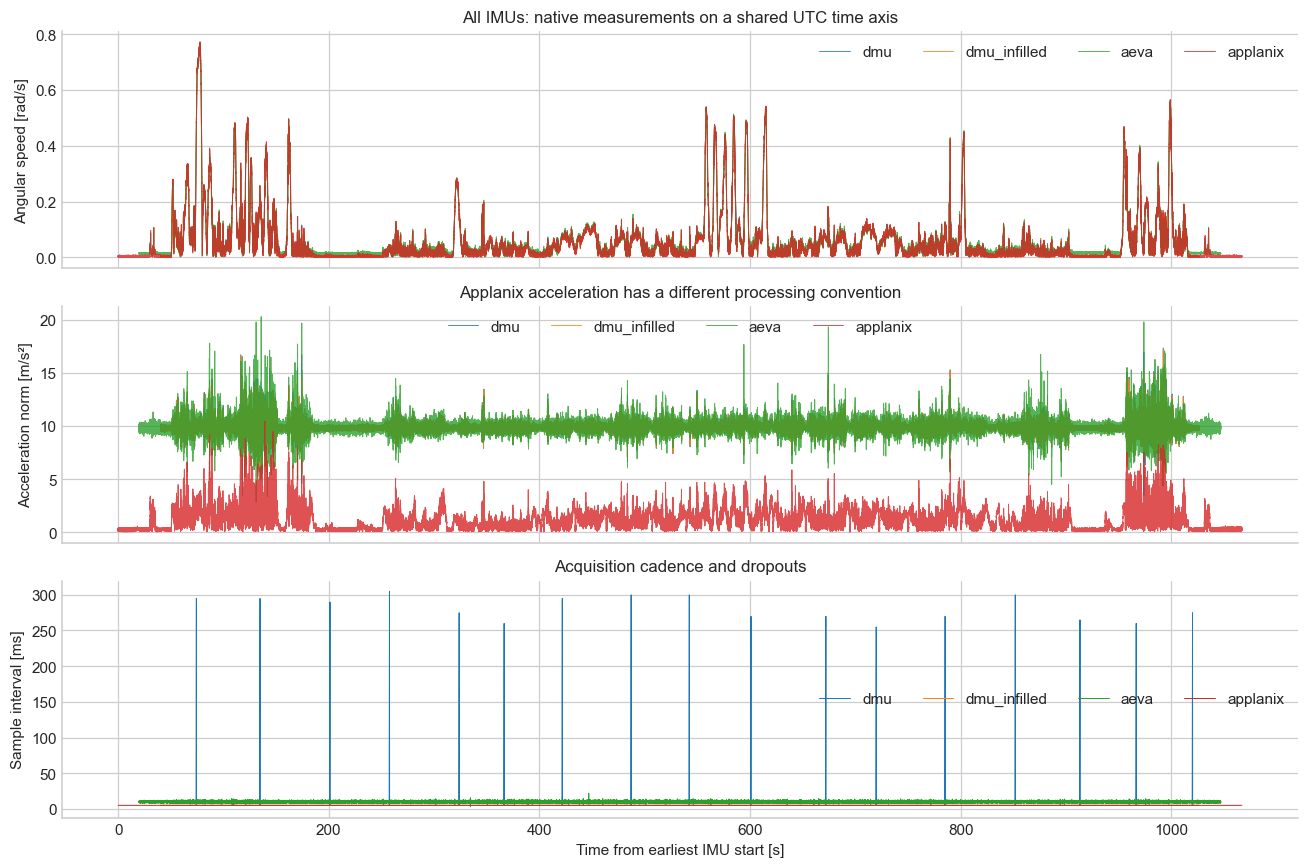

In [10]:
if imu_comparison:
    comparison_origin_ns = min(stream.timestamps_ns[0] for stream in imu_comparison.values() if len(stream.timestamps_ns))
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
    for source, stream in imu_comparison.items():
        elapsed = relative_seconds(stream.timestamps_ns, comparison_origin_ns)
        axes[0].plot(elapsed, np.linalg.norm(stream.data_gyr, axis=1), lw=.65, alpha=.8, label=source)
        axes[1].plot(elapsed, np.linalg.norm(stream.data_acc, axis=1), lw=.65, alpha=.8, label=source)
        axes[2].plot(elapsed[1:], np.diff(stream.timestamps_ns).astype(float) * 1e-6, lw=.65, label=source)
    axes[0].set(ylabel="Angular speed [rad/s]", title="All IMUs: native measurements on a shared UTC time axis")
    axes[1].set(ylabel="Acceleration norm [m/s²]", title="Applanix acceleration has a different processing convention")
    axes[2].set(xlabel="Time from earliest IMU start [s]", ylabel="Sample interval [ms]", title="Acquisition cadence and dropouts")
    for ax in axes:
        ax.legend(ncol=4)
    show_figure(fig)

**Sensor choices for later experiments**

- **Raw DMU41:** independent 200 Hz input; keep its measured dropouts and reject/split affected calibration windows.
- **Aeva IMU:** independent auxiliary 100 Hz input in its own frame; useful alongside the Aeva LiDAR and for multi-IMU work.
- **Infilled DMU:** an alternative preprocessing of the same DMU sensor. Do not count raw and infilled DMU as two independent physical sensors.
- **Applanix IMU:** reference diagnostics only when evaluating against Applanix-derived ground truth. Its shared provenance and processed acceleration preclude treating it as independent raw IMU input.

Selection should use common time coverage and observed gaps, not the smallest full-recording signal variance.

### Verify extrinsic direction against the actual reference files
For these Boreas files the hypothesis is `T_world_sensor = T_world_applanix @ T_applanix_sensor`. Compare it with the inverse hypothesis, rather than inferring direction from a filename. The official [evaluation code](https://github.com/utiasASRL/pyboreas/blob/master/pyboreas/utils/odometry.py) applies `T_applanix_lidar` on the left of a world-to-LiDAR pose, and composes `T_applanix_lidar @ inverse(T_aeva_lidar)` for Aeva.

The check below establishes consistency between provided files, not independent calibration accuracy. There is no DMU pose CSV in this download; its extrinsic follows the Boreas convention and cannot be independently verified by this trajectory check.

In [11]:
from boreas_dataset.calibration import calibration_direction_diagnostics
if (sequence.root / "applanix/gps_post_process.csv").is_file():
    display(pd.DataFrame(calibration_direction_diagnostics(sequence.root)))
else:
    print("No Applanix reference trajectory is available for a direction-consistency check.")

,source,hypothesis,samples,median_position_error_m,median_rotation_error_deg
0,velodyne,stored convention,60,0.000003,0.000128
1,velodyne,inverse convention,60,0.260000,85.391955
2,aeva,stored convention,60,0.000003,0.000112
3,aeva,inverse convention,60,0.713850,178.738578


The next notebook explores a common IMU/LiDAR time window, raw point clouds, relative ground-truth motion, and a small accumulation. Missing radar/camera processing  are intentionally outside this package's current scope.